<a href="https://colab.research.google.com/github/nastanelina143-dot/sales-analysis-python/blob/main/Python_for_DA_Module_Task.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [ ]:
countries = pd.read_csv("/content/drive/MyDrive/Mate_homework/countries.csv")
events = pd.read_csv("/content/drive/MyDrive/Mate_homework/events.csv")
products = pd.read_csv("/content/drive/MyDrive/Mate_homework/products.csv")

#Data overview
##Countries

In [ ]:
countries.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 249 entries, 0 to 248
Data columns (total 5 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   name        249 non-null    object
 1   alpha-2     248 non-null    object
 2   alpha-3     249 non-null    object
 3   region      248 non-null    object
 4   sub-region  248 non-null    object
dtypes: object(5)
memory usage: 9.9+ KB


In [ ]:
countries.head()

,name,alpha-2,alpha-3,region,sub-region
0,Afghanistan,AF,AFG,Asia,Southern Asia
1,Åland Islands,AX,ALA,Europe,Northern Europe
2,Albania,AL,ALB,Europe,Southern Europe
3,Algeria,DZ,DZA,Africa,Northern Africa
4,American Samoa,AS,ASM,Oceania,Polynesia


In [ ]:
countries.nunique()

,0
name,249
alpha-2,248
alpha-3,249
region,5
sub-region,17


##General description of Dataset "Countries"
One country or territory per row, 249 rows, and 5 columns.
- “name” has 249 unique values; there are no missing values. This is the full name of the country.
- “alpha-2” has 248 values out of 249; there is one missing value. This is the two-letter country code.
- alpha-3 has 249 unique values, with no missing entries. This is the three-letter country code.
- region has 5 values (Africa, Americas, Asia, Europe, Oceania) and one missing entry. This is a major world region.
- sub-region has 17 values (ranging from Sub-Saharan Africa with 53 countries to Central Asia with 5) and also one gap. This is a finer subdivision within a region.



##Products

In [ ]:
products.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 12 entries, 0 to 11
Data columns (total 2 columns):
 #   Column     Non-Null Count  Dtype 
---  ------     --------------  ----- 
 0   id         12 non-null     int64 
 1   item_type  12 non-null     object
dtypes: int64(1), object(1)
memory usage: 324.0+ bytes


In [ ]:
products.head(12)

,id,item_type
0,2103,Cereal
1,7940,Household
2,2455,Clothes
3,1270,Beverages
4,8681,Office Supplies
5,4594,Fruits
6,5988,Vegetables
7,7331,Baby Food
8,8875,Meat
9,8293,Cosmetics


In [ ]:
products['item_type'].value_counts()

,count
item_type,
Cereal,1
Household,1
Clothes,1
Beverages,1
Office Supplies,1
Fruits,1
Vegetables,1
Baby Food,1
Meat,1


##General description of Dataset "Products"
In this dataset, which contains 12 rows and two columns, we have a reference table with product names and their unique IDs.

Product categories included in this dataset: Cereal, Household, Clothes, Beverages, Office Supplies, Fruits, Vegetables, Baby Food, Meat, Cosmetics, Snacks, Personal Care.

##Events

In [ ]:
events.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1330 entries, 0 to 1329
Data columns (total 10 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   Order ID        1330 non-null   int64  
 1   Order Date      1330 non-null   object 
 2   Ship Date       1330 non-null   object 
 3   Order Priority  1330 non-null   object 
 4   Country Code    1248 non-null   object 
 5   Product ID      1330 non-null   int64  
 6   Sales Channel   1330 non-null   object 
 7   Units Sold      1328 non-null   float64
 8   Unit Price      1330 non-null   float64
 9   Unit Cost       1330 non-null   float64
dtypes: float64(3), int64(2), object(5)
memory usage: 104.0+ KB


In [ ]:
events.head()

,Order ID,Order Date,Ship Date,Order Priority,Country Code,Product ID,Sales Channel,Units Sold,Unit Price,Unit Cost
0,100640618,10/8/2014,10/18/2014,M,NOR,2103,Online,650.0,205.70,117.11
1,100983083,8/11/2016,8/11/2016,C,SRB,2103,Offline,1993.0,205.70,117.11
2,101025998,7/18/2014,8/11/2014,M,NaN,7940,Online,4693.0,668.27,502.54
3,102230632,5/13/2017,6/13/2017,L,MNE,2455,Online,1171.0,109.28,35.84
4,103435266,8/11/2012,9/18/2012,H,SRB,1270,Offline,7648.0,47.45,31.79


In [ ]:
events['Order Priority'].value_counts()

,count
Order Priority,
M,353
H,335
L,334
C,305
C,2
M,1


In [ ]:
events['Sales Channel'].value_counts()

,count
Sales Channel,
Offline,667
Online,660
online,3


##General description of Dataset "Products"
A table of sales transactions: 1330 rows and 10 columns. Each row is one order. Dtypes: int64 (2), float64 (3), object (5).

- Order ID — order number (int64), no missing values.
- Order Date — date the order was placed; stored as text (object) in M/D/YYYY format, needs conversion to datetime.
- Ship Date — date the order was shipped; same issue as Order Date.
- Order Priority — priority level of the order (H, M, L, C; probably High, Medium, Low, Critical). No missing values, but some values are spelled inconsistently (2 and 1 records) → duplicates to clean later.
- Country Code — three-letter country code (**matches alpha-3 in countries**); 82 missing values.
- Product ID — product category code (int64), **matches id in products.**
- Sales Channel — Online or Offline. Online is also written as “online” (3 records) → case duplicate to clean later.
- Units Sold — number of units sold; 2 missing values; float64 because of NaN.
- Unit Price — selling price per unit (float64).
- Unit Cost — cost per unit (float64).

The tables will be joined with a left join on events as the main table: Country Code (events) ↔ alpha-3 (countries) and Product ID (events) ↔ id (products).


#Data cleaning
##Products

In [ ]:
products.info()
products.head()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 12 entries, 0 to 11
Data columns (total 2 columns):
 #   Column     Non-Null Count  Dtype 
---  ------     --------------  ----- 
 0   id         12 non-null     int64 
 1   item_type  12 non-null     object
dtypes: int64(1), object(1)
memory usage: 324.0+ bytes


,id,item_type
0,2103,Cereal
1,7940,Household
2,2455,Clothes
3,1270,Beverages
4,8681,Office Supplies


In [ ]:
products.isna().sum()

,0
id,0
item_type,0


In [ ]:
products.duplicated().sum()

np.int64(0)

In [ ]:
products['item_type'].str.lower().str.strip().duplicated().sum()

np.int64(0)

In [ ]:
products['id'].unique()

array([2103, 7940, 2455, 1270, 8681, 4594, 5988, 7331, 8875, 8293, 8969,
       3127])

In [ ]:
products['item_type'].unique()

array(['Cereal', 'Household', 'Clothes', 'Beverages', 'Office Supplies',
       'Fruits', 'Vegetables', 'Baby Food', 'Meat', 'Cosmetics', 'Snacks',
       'Personal Care'], dtype=object)

No cleaning is needed: there are no missing values, no duplicate rows, id values are unique and the category names have no extra spaces or case inconsistencies. Data types are correct (id is int64, item_type is object), so no renaming or type conversion is required.

##Countries

In [ ]:
countries.info()
countries.head()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 249 entries, 0 to 248
Data columns (total 5 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   name        249 non-null    object
 1   alpha-2     248 non-null    object
 2   alpha-3     249 non-null    object
 3   region      248 non-null    object
 4   sub-region  248 non-null    object
dtypes: object(5)
memory usage: 9.9+ KB


,name,alpha-2,alpha-3,region,sub-region
0,Afghanistan,AF,AFG,Asia,Southern Asia
1,Åland Islands,AX,ALA,Europe,Northern Europe
2,Albania,AL,ALB,Europe,Southern Europe
3,Algeria,DZ,DZA,Africa,Northern Africa
4,American Samoa,AS,ASM,Oceania,Polynesia


In [ ]:
countries.isna().sum() / countries.shape[0]

,0
name,0.000000
alpha-2,0.004016
alpha-3,0.000000
region,0.004016
sub-region,0.004016


In [ ]:
countries_na = countries[(countries['region'].isna()) | (countries['alpha-2'].isna())]
countries_na

,name,alpha-2,alpha-3,region,sub-region
8,Antarctica,AQ,ATA,NaN,NaN
153,Namibia,NaN,NAM,Africa,Sub-Saharan Africa


In [ ]:
countries['region'] = countries['region'].fillna("Unknown")
countries['sub-region'] = countries['sub-region'].fillna("Unknown")
countries['alpha-2'] = countries['alpha-2'].fillna("NA")
countries[(countries['region'] == "Unknown") | (countries['alpha-2'] == "NA")]

,name,alpha-2,alpha-3,region,sub-region
8,Antarctica,AQ,ATA,Unknown,Unknown
153,Namibia,NA,NAM,Africa,Sub-Saharan Africa


In [ ]:
countries.duplicated().sum()

np.int64(0)

In [ ]:
countries['name'].str.lower().str.strip().duplicated().sum()

np.int64(0)

Missing values were found in alpha-2 (1 value), region (1 value) and sub-region (1 value), which is below 5% of rows. The rows are not deleted, because they may be needed in the further analysis. It will be decided after the tables are merged whether they are relevant. At this stage, the unfilled values were renamed to "Unknown" for region Antarctica and "NA" for Namibia.
All columns have the object type, which is correct for text values (country names, codes, regions). No type conversion is needed.
No duplicates were found: there are no fully duplicated rows, and the values have no extra spaces or case differences

##Events

In [ ]:
events.info()
events.head()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1330 entries, 0 to 1329
Data columns (total 10 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   Order ID        1330 non-null   int64  
 1   Order Date      1330 non-null   object 
 2   Ship Date       1330 non-null   object 
 3   Order Priority  1330 non-null   object 
 4   Country Code    1248 non-null   object 
 5   Product ID      1330 non-null   int64  
 6   Sales Channel   1330 non-null   object 
 7   Units Sold      1328 non-null   float64
 8   Unit Price      1330 non-null   float64
 9   Unit Cost       1330 non-null   float64
dtypes: float64(3), int64(2), object(5)
memory usage: 104.0+ KB


,Order ID,Order Date,Ship Date,Order Priority,Country Code,Product ID,Sales Channel,Units Sold,Unit Price,Unit Cost
0,100640618,10/8/2014,10/18/2014,M,NOR,2103,Online,650.0,205.70,117.11
1,100983083,8/11/2016,8/11/2016,C,SRB,2103,Offline,1993.0,205.70,117.11
2,101025998,7/18/2014,8/11/2014,M,NaN,7940,Online,4693.0,668.27,502.54
3,102230632,5/13/2017,6/13/2017,L,MNE,2455,Online,1171.0,109.28,35.84
4,103435266,8/11/2012,9/18/2012,H,SRB,1270,Offline,7648.0,47.45,31.79


In [ ]:
events.isna().sum() / events.shape[0] * 100

,0
Order ID,0.000000
Order Date,0.000000
Ship Date,0.000000
Order Priority,0.000000
Country Code,6.165414
Product ID,0.000000
Sales Channel,0.000000
Units Sold,0.150376
Unit Price,0.000000
Unit Cost,0.000000


In [ ]:
events['Order Date'] = pd.to_datetime(events['Order Date'])
events['Ship Date'] = pd.to_datetime(events['Ship Date'])

In [ ]:
events.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1330 entries, 0 to 1329
Data columns (total 10 columns):
 #   Column          Non-Null Count  Dtype         
---  ------          --------------  -----         
 0   Order ID        1330 non-null   int64         
 1   Order Date      1330 non-null   datetime64[ns]
 2   Ship Date       1330 non-null   datetime64[ns]
 3   Order Priority  1330 non-null   object        
 4   Country Code    1248 non-null   object        
 5   Product ID      1330 non-null   int64         
 6   Sales Channel   1330 non-null   object        
 7   Units Sold      1328 non-null   float64       
 8   Unit Price      1330 non-null   float64       
 9   Unit Cost       1330 non-null   float64       
dtypes: datetime64[ns](2), float64(3), int64(2), object(3)
memory usage: 104.0+ KB


In [ ]:
events['Order Priority'].value_counts()

,count
Order Priority,
M,353
H,335
L,334
C,305
C,2
M,1


In [ ]:
events['Order Priority'] = events['Order Priority'].str.strip()
events['Order Priority'].value_counts()

,count
Order Priority,
M,354
H,335
L,334
C,307


In [ ]:
events['Order Priority'] = events['Order Priority'].map({'M': 'Medium', 'H': 'High', 'L': 'Low', 'C': 'Critical'})
events.head()

,Order ID,Order Date,Ship Date,Order Priority,Country Code,Product ID,Sales Channel,Units Sold,Unit Price,Unit Cost
0,100640618,2014-10-08,2014-10-18,Medium,NOR,2103,Online,650.0,205.70,117.11
1,100983083,2016-08-11,2016-08-11,Critical,SRB,2103,Offline,1993.0,205.70,117.11
2,101025998,2014-07-18,2014-08-11,Medium,NaN,7940,Online,4693.0,668.27,502.54
3,102230632,2017-05-13,2017-06-13,Low,MNE,2455,Online,1171.0,109.28,35.84
4,103435266,2012-08-11,2012-09-18,High,SRB,1270,Offline,7648.0,47.45,31.79


In [ ]:
print(events['Country Code'].nunique())
print(events['Country Code'].str.lower().str.strip().nunique())

45
45


In [ ]:
events['Country Code'] = events['Country Code'].fillna("Unknown")

In [ ]:
events.head()

,Order ID,Order Date,Ship Date,Order Priority,Country Code,Product ID,Sales Channel,Units Sold,Unit Price,Unit Cost
0,100640618,2014-10-08,2014-10-18,Medium,NOR,2103,Online,650.0,205.70,117.11
1,100983083,2016-08-11,2016-08-11,Critical,SRB,2103,Offline,1993.0,205.70,117.11
2,101025998,2014-07-18,2014-08-11,Medium,Unknown,7940,Online,4693.0,668.27,502.54
3,102230632,2017-05-13,2017-06-13,Low,MNE,2455,Online,1171.0,109.28,35.84
4,103435266,2012-08-11,2012-09-18,High,SRB,1270,Offline,7648.0,47.45,31.79


In [ ]:
print(events['Product ID'].unique())


[2103 7940 2455 1270 8681 4594 5988 7331 8875 8293 8969 3127]


In [ ]:
events['Order ID'].duplicated().sum()

np.int64(0)

In [ ]:
events['Order ID'].astype(str).str.strip().duplicated().sum()

np.int64(0)

In [ ]:
events['Sales Channel'].value_counts()

,count
Sales Channel,
Offline,667
Online,660
online,3


In [ ]:
events['Sales Channel'] = events['Sales Channel'].str.title().str.strip()

In [ ]:
events['Sales Channel'].value_counts()

,count
Sales Channel,
Offline,667
Online,663


In [ ]:
events[events['Units Sold'].isna()]

,Order ID,Order Date,Ship Date,Order Priority,Country Code,Product ID,Sales Channel,Units Sold,Unit Price,Unit Cost
183,217165648,2014-05-20,2014-06-08,Medium,ESP,8875,Offline,NaN,421.89,364.69
319,309655511,2014-05-05,2014-05-21,Critical,HRV,3127,Offline,NaN,81.73,56.67


In [ ]:
events = events.dropna(subset='Units Sold')

In [ ]:
events.info()

<class 'pandas.core.frame.DataFrame'>
Index: 1328 entries, 0 to 1329
Data columns (total 10 columns):
 #   Column          Non-Null Count  Dtype         
---  ------          --------------  -----         
 0   Order ID        1328 non-null   int64         
 1   Order Date      1328 non-null   datetime64[ns]
 2   Ship Date       1328 non-null   datetime64[ns]
 3   Order Priority  1328 non-null   object        
 4   Country Code    1328 non-null   object        
 5   Product ID      1328 non-null   int64         
 6   Sales Channel   1328 non-null   object        
 7   Units Sold      1328 non-null   float64       
 8   Unit Price      1328 non-null   float64       
 9   Unit Cost       1328 non-null   float64       
dtypes: datetime64[ns](2), float64(3), int64(2), object(3)
memory usage: 114.1+ KB


In [ ]:
events[['Units Sold',	'Unit Price',	'Unit Cost']].describe()

,Units Sold,Unit Price,Unit Cost
count,1328.000000,1328.000000,1328.000000
mean,4952.201807,264.913245,187.211521
std,2905.198996,217.386320,176.187801
min,2.000000,9.330000,6.920000
25%,2356.750000,81.730000,35.840000
50%,4962.000000,154.060000,97.440000
75%,7459.500000,437.200000,263.330000
max,9999.000000,668.270000,524.960000


In [ ]:
diff = events['Unit Price'] - events['Unit Cost']

In [ ]:
diff[diff < 0]

,0


In [ ]:
(events['Ship Date'] < events['Order Date']).sum()

np.int64(0)

Missing values.

- Country Code: 82 missing values (~ 6.2% of rows). The rows were kept and the missing codes were replaced with “Unknown”.
- Units Sold: The 2 rows were deleted.

Data types.

- Order Date and Ship Date were converted to datetime.

Duplicates.

- Order Priority: After strip() there are 4 categories instead of 6. The letter codes were then replaced with readable names.
- Sales Channel: “online” in lowercase (3 records) was merged with “Online”.
- Country Code: 45 unique values before and after normalization, so there are no hidden duplicates.
- Product ID: 12 unique values, the same as in products, so no products were lost.
- Order Id: No duplicates were found as well.

Anomalies.

- Unit Price is never lower than Unit Cost.
- Ship Date is never earlier than Order Date.
- describe() shows no negative or impossible values in Units Sold, Unit Price and Unit Cost.

#Data analysis and visualization

In [ ]:
data = events.merge(countries, left_on='Country Code', right_on='alpha-3', how='left')

In [ ]:
data = data.merge(products, left_on='Product ID', right_on='id', how='left')

In [ ]:
data.head()

,Order ID,Order Date,Ship Date,Order Priority,Country Code,Product ID,Sales Channel,Units Sold,Unit Price,Unit Cost,name,alpha-2,alpha-3,region,sub-region,id,item_type
0,100640618,2014-10-08,2014-10-18,Medium,NOR,2103,Online,650.0,205.70,117.11,Norway,NO,NOR,Europe,Northern Europe,2103,Cereal
1,100983083,2016-08-11,2016-08-11,Critical,SRB,2103,Offline,1993.0,205.70,117.11,Serbia,RS,SRB,Europe,Southern Europe,2103,Cereal
2,101025998,2014-07-18,2014-08-11,Medium,Unknown,7940,Online,4693.0,668.27,502.54,NaN,NaN,NaN,NaN,NaN,7940,Household
3,102230632,2017-05-13,2017-06-13,Low,MNE,2455,Online,1171.0,109.28,35.84,Montenegro,ME,MNE,Europe,Southern Europe,2455,Clothes
4,103435266,2012-08-11,2012-09-18,High,SRB,1270,Offline,7648.0,47.45,31.79,Serbia,RS,SRB,Europe,Southern Europe,1270,Beverages


In [ ]:
data = data.drop(columns=['alpha-2', 'alpha-3', 'id'])

In [ ]:
data = data.rename(columns={'name': 'country', 'item_type': 'category'})

In [ ]:
data.columns = data.columns.str.replace(' ', '_').str.replace('-', '_').str.lower()

In [ ]:
data[['country',	'region',	'sub_region']] = data[['country',	'region',	'sub_region']].fillna('Unknown')

In [ ]:
data.head()

,order_id,order_date,ship_date,order_priority,country_code,product_id,sales_channel,units_sold,unit_price,unit_cost,country,region,sub_region,category
0,100640618,2014-10-08,2014-10-18,Medium,NOR,2103,Online,650.0,205.70,117.11,Norway,Europe,Northern Europe,Cereal
1,100983083,2016-08-11,2016-08-11,Critical,SRB,2103,Offline,1993.0,205.70,117.11,Serbia,Europe,Southern Europe,Cereal
2,101025998,2014-07-18,2014-08-11,Medium,Unknown,7940,Online,4693.0,668.27,502.54,Unknown,Unknown,Unknown,Household
3,102230632,2017-05-13,2017-06-13,Low,MNE,2455,Online,1171.0,109.28,35.84,Montenegro,Europe,Southern Europe,Clothes
4,103435266,2012-08-11,2012-09-18,High,SRB,1270,Offline,7648.0,47.45,31.79,Serbia,Europe,Southern Europe,Beverages


##Key metrics

In [ ]:
data['revenue'] = data['units_sold'] * data['unit_price']
data['cost'] = data['units_sold'] * data['unit_cost']
data['profit'] = data['revenue'] - data['cost']


In [ ]:
data.head()

,order_id,order_date,ship_date,order_priority,country_code,product_id,sales_channel,units_sold,unit_price,unit_cost,country,region,sub_region,category,revenue,cost,profit
0,100640618,2014-10-08,2014-10-18,Medium,NOR,2103,Online,650.0,205.70,117.11,Norway,Europe,Northern Europe,Cereal,133705.00,76121.50,57583.50
1,100983083,2016-08-11,2016-08-11,Critical,SRB,2103,Offline,1993.0,205.70,117.11,Serbia,Europe,Southern Europe,Cereal,409960.10,233400.23,176559.87
2,101025998,2014-07-18,2014-08-11,Medium,Unknown,7940,Online,4693.0,668.27,502.54,Unknown,Unknown,Unknown,Household,3136191.11,2358420.22,777770.89
3,102230632,2017-05-13,2017-06-13,Low,MNE,2455,Online,1171.0,109.28,35.84,Montenegro,Europe,Southern Europe,Clothes,127966.88,41968.64,85998.24
4,103435266,2012-08-11,2012-09-18,High,SRB,1270,Offline,7648.0,47.45,31.79,Serbia,Europe,Southern Europe,Beverages,362897.60,243129.92,119767.68


In [ ]:
data_un = data[data['country'] != 'Unknown'].copy()

In [ ]:
print(f"Total amount of orders: {data_un.shape[0]}")
print(f"Total amount of sold units: {data_un['units_sold'].sum()}")
print(f"Total revenue: {data_un['revenue'].sum()}")
print(f"Total cost: {round(data_un['cost'].sum(), 2)}")
print(f"Total profit: {data_un['profit'].sum()}")

print(f"Total countries: {data_un['country'].nunique()}")

print(f"Total regions: {data_un['region'].nunique()}")

print(f"Total sub-regions: {data_un['sub_region'].nunique()}")

Total amount of orders: 1246
Total amount of sold units: 6171671.0
Total revenue: 1598983761.26
Total cost: 1125274726.2
Total profit: 473709035.06
Total countries: 45
Total regions: 2
Total sub-regions: 5


In the events table, 82 orders (about 6% of all orders) have no country code. Because this share is too large to simply delete, these orders were kept in the dataset and their missing codes were replaced with “Unknown”. However, all further analysis (key metrics, product categories, countries, regions, sales channels, shipping time, dynamics and weekdays) is based only on orders with a known country (1,246 orders), so that all parts of the report are consistent and can be compared with each other. The excluded orders are not deleted: they are kept in the dataset and analysed separately below.

In [ ]:
data_nan = data[data['country'] == 'Unknown']

In [ ]:
print(f"Total amount of orders: {data_nan.shape[0]}")
print(f"Total amount of sold units: {data_nan['units_sold'].sum()}")
print(f"Total revenue: {round(data_nan['revenue'].sum(), 2)}")
print(f"Total cost: {round(data_nan['cost'].sum(), 2)}")
print(f"Total profit: {data_nan['profit'].sum()}")

print(f"Amount of unknown countries: {data_nan.shape[0]}")


Total amount of orders: 82
Total amount of sold units: 404853.0
Total revenue: 103145646.95
Total cost: 75420223.01
Total profit: 27725423.94
Amount of unknown countries: 82


The orders with an unknown country are about 6% of all orders (82 of 1,328), about 6% of revenue (103 million of 1,702 million) and about 5.5% of profit (27.7 million of 501.4 million).

#Sales Analysis

###Visualisations of key metrics by category

In [ ]:
plt.style.use('ggplot')

In [ ]:
rev_cos_grouped_by_cat = data_un.groupby('category')[['revenue', 'cost']].sum().sort_values(by='revenue', ascending=False).reset_index()
rev_cos_melted = rev_cos_grouped_by_cat.melt(id_vars='category', var_name='metric', value_name='amount')
rev_cos_melted['amount'] = rev_cos_melted['amount'] / 1000000
rev_cos_melted

,category,metric,amount
0,Office Supplies,revenue,378.666242
1,Household,revenue,278.874417
2,Cosmetics,revenue,221.305394
3,Meat,revenue,201.339830
4,Baby Food,revenue,133.834369
5,Cereal,revenue,94.676716
6,Vegetables,revenue,82.038491
7,Snacks,revenue,69.213492
8,Clothes,revenue,63.307325
9,Personal Care,revenue,43.346323


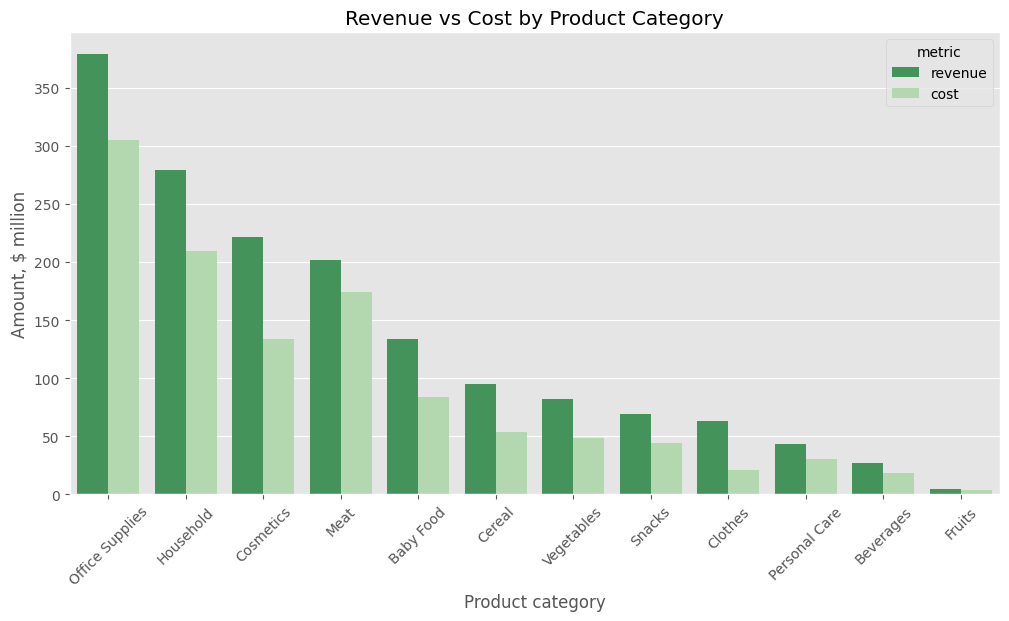

In [ ]:
plt.figure(figsize=(12, 6))
sns.barplot(data=rev_cos_melted, x='category', y='amount', hue='metric', palette='Greens_r')
plt.title("Revenue vs Cost by Product Category")
plt.xlabel('Product category')
plt.ylabel('Amount, $ million')
plt.xticks(rotation=45)
plt.show()

The leader in revenue (over $400 million) is Office Supplies, followed by Household, Cosmetics, and Meat. The smallest volumes are in Fruits and Beverages. The largest absolute gap between revenue and expenses is in Office Supplies, Cosmetics, and Household, so these categories account for the lion’s share of profit.

In [ ]:
prof_grouped_by_cat = data_un.groupby('category')['profit'].sum().sort_values(ascending=False).reset_index()
prof_grouped_by_cat['profit'] = prof_grouped_by_cat['profit'] / 1000000

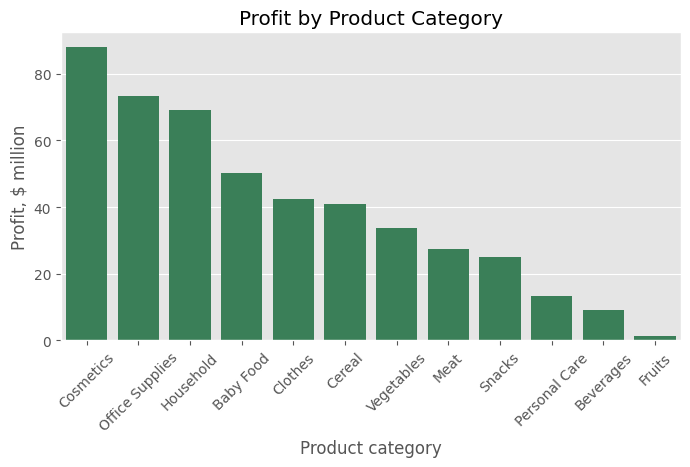

In [ ]:
plt.figure(figsize=(8, 4))
sns.barplot(data=prof_grouped_by_cat, x='category', y='profit', color='seagreen')
plt.title("Profit by Product Category")
plt.xlabel('Product category')
plt.ylabel('Profit, $ million')
plt.xticks(rotation=45)
plt.show()

Cosmetics generates the most profit (over $90 million), followed by Office Supplies and Household. Together, these three categories account for the majority of the company's profit. Fruits, Beverages, and Personal Care generate the least profit.

In [ ]:
items_grouped_by_cat = data_un.groupby('category')['units_sold'].sum().sort_values(ascending=False).reset_index()
items_grouped_by_cat['units_sold'] = items_grouped_by_cat['units_sold'] / 1000
items_grouped_by_cat

,category,units_sold
0,Office Supplies,581.481
1,Clothes,579.313
2,Beverages,577.991
3,Vegetables,532.510
4,Fruits,531.135
5,Personal Care,530.360
6,Baby Food,524.265
7,Cosmetics,506.188
8,Meat,477.233
9,Cereal,460.266


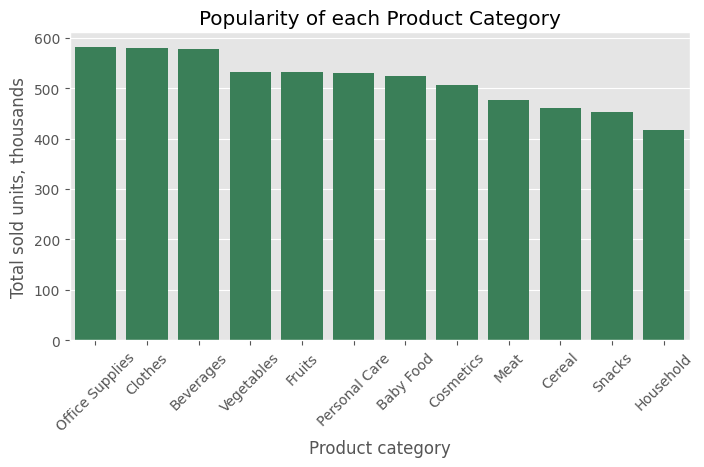

In [ ]:
plt.figure(figsize=(8, 4))
sns.barplot(data=items_grouped_by_cat, x='category', y='units_sold', color='seagreen')
plt.title("Popularity of each Product Category")
plt.xlabel('Product category')
plt.ylabel('Total sold units, thousands')
plt.xticks(rotation=45)
plt.show()

In [ ]:
margin_by_cat = data_un.groupby('category')[['revenue', 'profit']].sum()
margin_by_cat['margin, %'] = margin_by_cat['profit'] / margin_by_cat['revenue'] * 100
margin_by_cat = margin_by_cat.sort_values('margin, %')
margin_by_cat.round(1)

,revenue,profit,"margin, %"
category,,,
Meat,201339830.4,27297727.6,13.6
Office Supplies,378666242.0,73411976.2,19.4
Household,278874417.2,69160454.8,24.8
Fruits,4955489.6,1280035.4,25.8
Personal Care,43346322.8,13290821.6,30.7
Beverages,27425673.0,9051339.1,33.0
Snacks,69213492.2,25012661.9,36.1
Baby Food,133834369.2,50256042.9,37.6
Cosmetics,221305393.6,88010907.6,39.8


Units sold are spread evenly across categories, between about 420,000 and 580,000 units each, so popularity does not explain profit. The difference comes from the price of the products and the margin (see the table above): for example, Fruits, Beverages and Personal Care have low profit mostly because of small revenue, while Meat and Office Supplies have the lowest margin.

###Visualisations of key metrics by countries

In [ ]:
data.head()

,order_id,order_date,ship_date,order_priority,country_code,product_id,sales_channel,units_sold,unit_price,unit_cost,country,region,sub_region,category,revenue,cost,profit
0,100640618,2014-10-08,2014-10-18,Medium,NOR,2103,Online,650.0,205.70,117.11,Norway,Europe,Northern Europe,Cereal,133705.00,76121.50,57583.50
1,100983083,2016-08-11,2016-08-11,Critical,SRB,2103,Offline,1993.0,205.70,117.11,Serbia,Europe,Southern Europe,Cereal,409960.10,233400.23,176559.87
2,101025998,2014-07-18,2014-08-11,Medium,Unknown,7940,Online,4693.0,668.27,502.54,Unknown,Unknown,Unknown,Household,3136191.11,2358420.22,777770.89
3,102230632,2017-05-13,2017-06-13,Low,MNE,2455,Online,1171.0,109.28,35.84,Montenegro,Europe,Southern Europe,Clothes,127966.88,41968.64,85998.24
4,103435266,2012-08-11,2012-09-18,High,SRB,1270,Offline,7648.0,47.45,31.79,Serbia,Europe,Southern Europe,Beverages,362897.60,243129.92,119767.68


In [ ]:
rev_cos_by_country = data_un.groupby('country')[['revenue', 'cost']].sum().sort_values(by='revenue', ascending=False).head(10).reset_index()
rev_cos_by_country_melted = rev_cos_by_country.melt(id_vars='country', var_name='metric', value_name='amount')
rev_cos_by_country_melted['amount'] = rev_cos_by_country_melted['amount'] / 1000000
rev_cos_by_country_melted


,country,metric,amount
0,Czech Republic,revenue,53.543932
1,Ukraine,revenue,53.252318
2,Bosnia and Herzegovina,revenue,50.117508
3,Macedonia,revenue,49.222085
4,San Marino,revenue,47.883708
5,Andorra,revenue,47.756693
6,Portugal,revenue,47.172190
7,Malta,revenue,47.145321
8,Russia,revenue,46.051660
9,Slovakia,revenue,42.940998


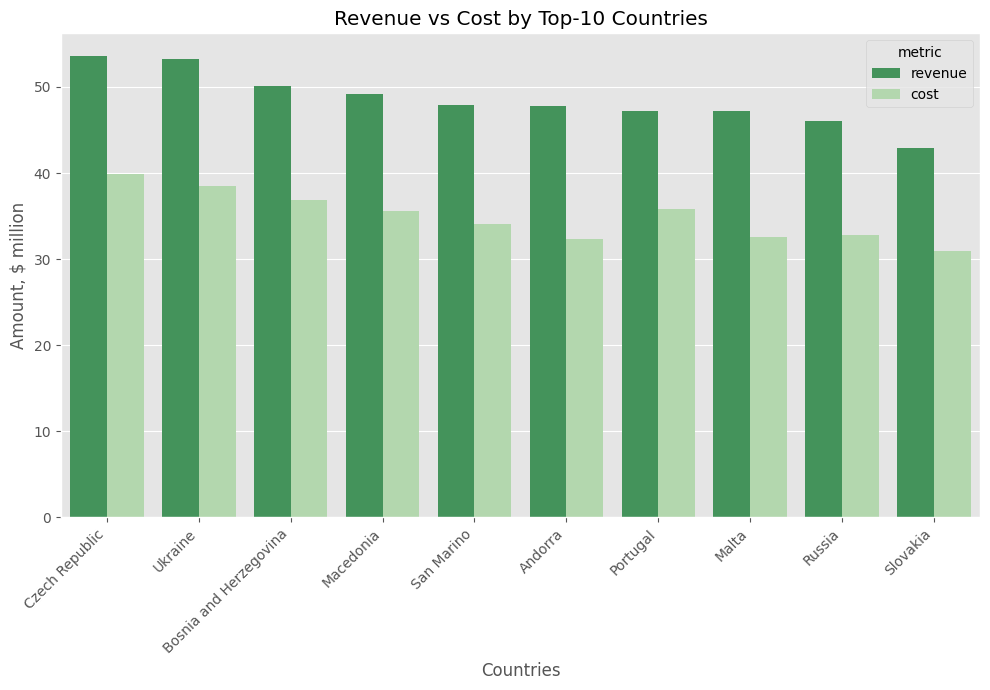

In [ ]:
plt.figure(figsize=(10, 7))
sns.barplot(data=rev_cos_by_country_melted, x='country', y='amount', hue='metric', palette='Greens_r')
plt.title("Revenue vs Cost by Top-10 Countries")
plt.xlabel('Countries')
plt.ylabel('Amount, $ million')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

The top-10 countries by revenue each generate between roughly 43 and 54 million. The Czech Republic and Ukraine lead with almost identical results, followed by Bosnia and Herzegovina and Macedonia. The gap between the first and the tenth country is moderate, so revenue is spread fairly evenly among the leaders. In every country the costs are clearly lower than the revenue, and the distance between the two bars looks similar across the top-10, so the profitability of these markets is comparable.

In [ ]:
profit_by_country = data_un.groupby('country')['profit'].sum().sort_values(ascending=False).head(10).reset_index()
profit_by_country['profit'] = profit_by_country['profit'] / 1000000
profit_by_country

,country,profit
0,Andorra,15.410037
1,Ukraine,14.804926
2,Malta,14.610128
3,San Marino,13.792993
4,Hungary,13.786231
5,Macedonia,13.684100
6,Czech Republic,13.635594
7,Russia,13.267683
8,Bosnia and Herzegovina,13.257603
9,Greece,12.324450


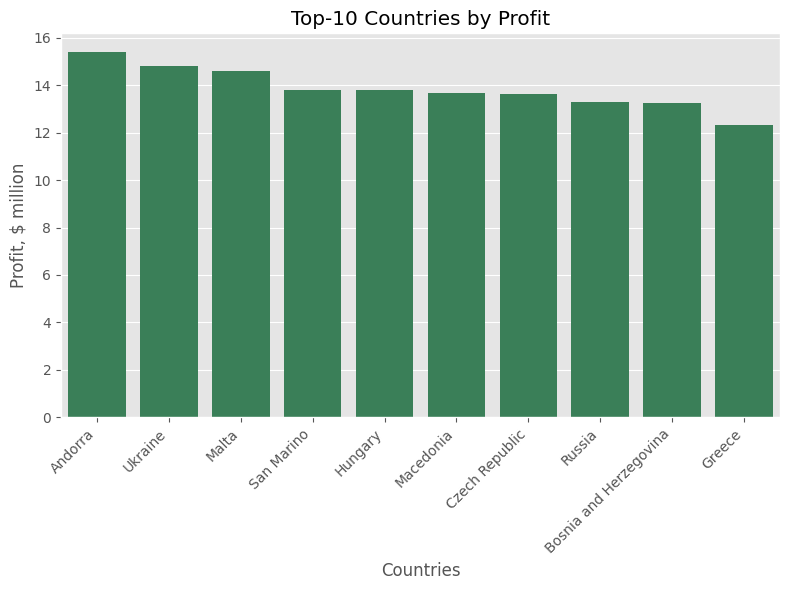

In [ ]:
plt.figure(figsize=(8, 6))
sns.barplot(data=profit_by_country, x='country', y='profit', color='seagreen')
plt.title("Top-10 Countries by Profit")
plt.xlabel('Countries')
plt.ylabel('Profit, $ million')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

The ranking by profit differs from the ranking by revenue. Andorra leads with about 15 million, followed by Ukraine and Malta, while the Czech Republic, the top country by revenue, falls to seventh place. This shows that the highest revenue does not guarantee the highest profit: a country can sell a bit less but earn more if its costs are lower. Profits of the top-10 countries fall in a narrow range of roughly 12 to 15 million, so no single market dominates.

In [ ]:
units_by_country = data_un.groupby('country')['units_sold'].sum().sort_values(ascending=False).head(10).reset_index()
top_countries = units_by_country['country'].tolist()
top_countries

['Macedonia',
 'San Marino',
 'Andorra',
 'Greece',
 'Malta',
 'Serbia',
 'Romania',
 'Russia',
 'Ukraine',
 'Cyprus']

In [ ]:
data_top = data_un[data_un['country'].isin(top_countries)]
data_top['country'].nunique()

10

In [ ]:
units_pivot = pd.pivot_table(data=data_top, index='country', columns='category', values='units_sold', aggfunc='sum', fill_value=0)
units_pivot = units_pivot / 1000
units_pivot

category,Baby Food,Beverages,Cereal,Clothes,Cosmetics,Fruits,Household,Meat,Office Supplies,Personal Care,Snacks,Vegetables
country,,,,,,,,,,,,
Andorra,19.818,29.262,16.505,8.117,24.145,13.601,23.532,7.355,3.020,8.809,18.748,12.774
Cyprus,0.802,8.383,1.790,31.672,2.864,15.863,16.080,14.753,3.636,25.137,22.336,15.427
Greece,13.788,24.363,26.429,9.440,16.144,28.672,11.245,8.209,9.047,16.410,0.480,12.632
Macedonia,19.725,39.284,8.563,17.767,0.869,15.694,17.814,15.378,19.574,6.489,23.340,18.581
Malta,30.499,8.905,9.229,0.000,34.133,21.425,3.062,18.728,11.116,12.245,9.994,14.305
Romania,24.962,10.565,12.962,15.554,8.801,19.438,3.530,13.769,7.679,24.372,22.441,2.809
Russia,13.734,12.508,1.944,25.606,13.073,9.127,7.488,7.392,29.251,17.195,23.517,5.119
San Marino,8.845,14.681,15.691,21.124,9.076,19.166,10.596,10.031,26.215,25.889,11.303,19.611
Serbia,6.798,29.035,11.579,13.657,4.508,9.102,6.115,14.798,22.770,0.000,13.157,38.850


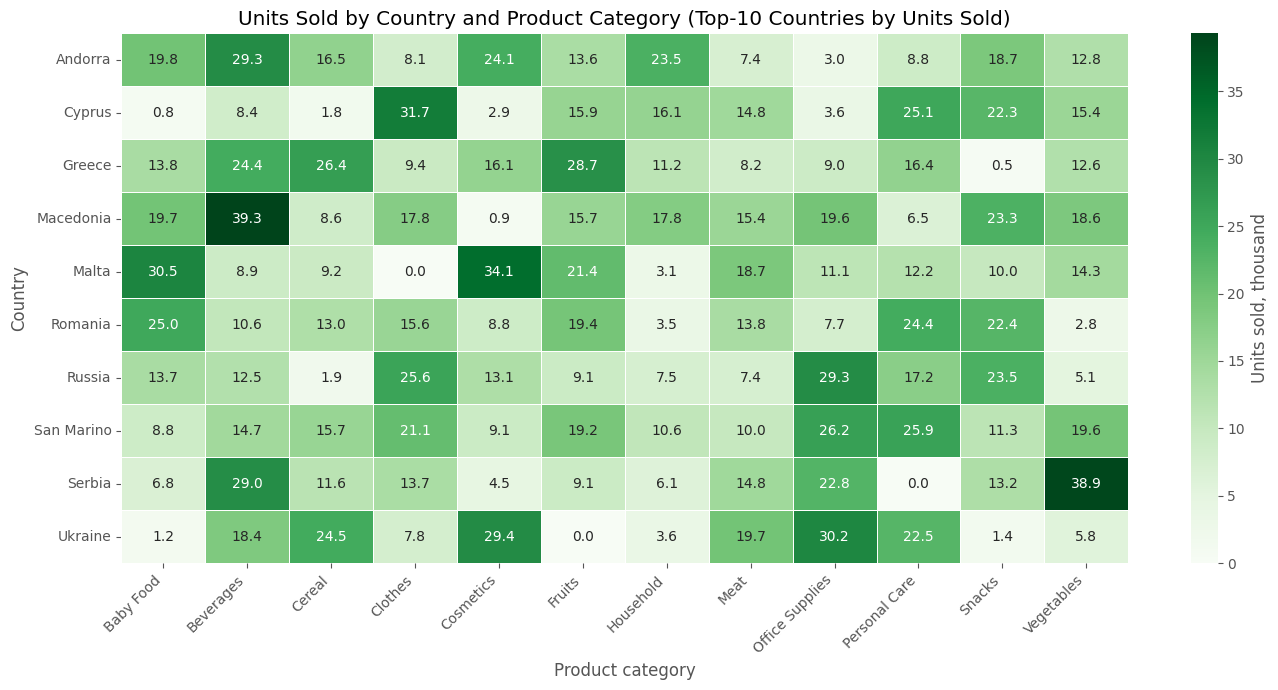

In [ ]:
plt.figure(figsize=(14, 7))
sns.heatmap(data=units_pivot, annot=True, fmt='.1f', cmap='Greens', linewidths=0.5, cbar_kws={'label': 'Units sold, thousand'})
plt.title('Units Sold by Country and Product Category (Top-10 Countries by Units Sold)')
plt.xlabel('Product category')
plt.ylabel('Country')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

The heatmap shows the number of units sold in each product category across the top-10 countries by units sold. The darker the cell, the more units were sold. The most popular combinations are Beverages in Macedonia, Vegetables in Serbia, Cosmetics in Malta and Clothes in Cyprus, each with roughly 32 to 39 thousand units. The lightest cells (for example Baby Food in Cyprus, Snacks in Greece, Cosmetics in Macedonia) mark categories with very low demand, and a few combinations have no sales at all.

###Visualisations of key metrics by regions

In [ ]:
data_un.head()

,order_id,order_date,ship_date,order_priority,country_code,product_id,sales_channel,units_sold,unit_price,unit_cost,country,region,sub_region,category,revenue,cost,profit
0,100640618,2014-10-08,2014-10-18,Medium,NOR,2103,Online,650.0,205.70,117.11,Norway,Europe,Northern Europe,Cereal,133705.00,76121.50,57583.50
1,100983083,2016-08-11,2016-08-11,Critical,SRB,2103,Offline,1993.0,205.70,117.11,Serbia,Europe,Southern Europe,Cereal,409960.10,233400.23,176559.87
3,102230632,2017-05-13,2017-06-13,Low,MNE,2455,Online,1171.0,109.28,35.84,Montenegro,Europe,Southern Europe,Clothes,127966.88,41968.64,85998.24
4,103435266,2012-08-11,2012-09-18,High,SRB,1270,Offline,7648.0,47.45,31.79,Serbia,Europe,Southern Europe,Beverages,362897.60,243129.92,119767.68
5,103450715,2015-03-15,2015-04-18,High,SVK,8681,Online,2220.0,651.21,524.96,Slovakia,Europe,Eastern Europe,Office Supplies,1445686.20,1165411.20,280275.00


In [ ]:
region_totals = data_un.groupby('region')[['revenue', 'cost', 'profit', 'units_sold']].sum().reset_index()
region_totals

,region,revenue,cost,profit,units_sold
0,Asia,9.333089e+07,6.817863e+07,2.515225e+07,410427.0
1,Europe,1.505653e+09,1.057096e+09,4.485568e+08,5761244.0


In [ ]:
region_totals['cost_share'] = region_totals['cost'] / region_totals['revenue'] * 100
region_totals['profit_share'] = region_totals['profit'] / region_totals['revenue'] * 100
region_totals

,region,revenue,cost,profit,units_sold,cost_share,profit_share
0,Asia,9.333089e+07,6.817863e+07,2.515225e+07,410427.0,73.050451,26.949549
1,Europe,1.505653e+09,1.057096e+09,4.485568e+08,5761244.0,70.208486,29.791514


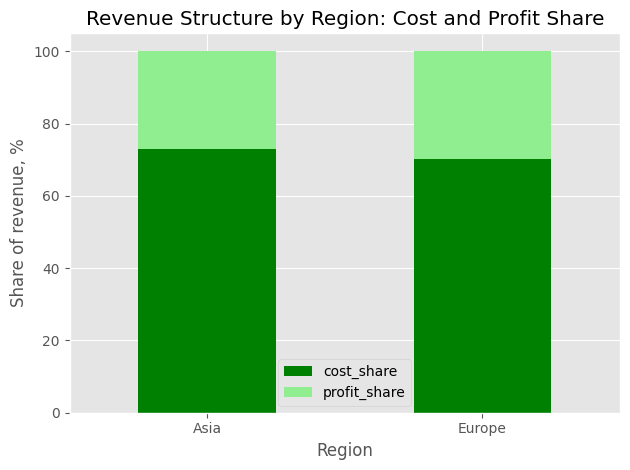

In [ ]:
region_totals[['region', 'cost_share', 'profit_share']].set_index('region').plot(kind='bar', stacked=True, color=['green', 'lightgreen'])
plt.title('Revenue Structure by Region: Cost and Profit Share')
plt.xlabel('Region')
plt.ylabel('Share of revenue, %')
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

The chart shows how revenue is split between costs and profit in each region. In both regions costs take the larger part of revenue: about 73% in Asia and about 70% in Europe, which leaves roughly 27% and 30% as profit. Europe is therefore slightly more efficient, but the difference is small, so the two regions work with a similar margin. The chart uses shares rather than absolute values because Europe is much larger than Asia (about 1.5 billion in revenue against about 93 million), and absolute bars would make Asia almost invisible.

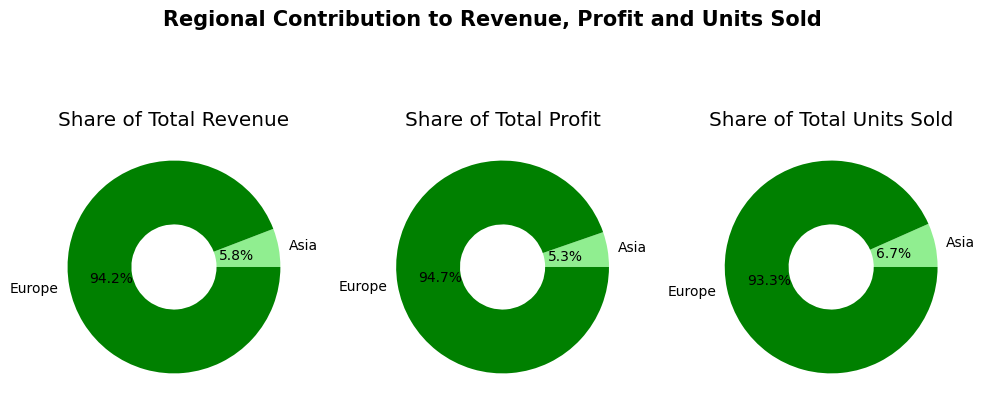

In [ ]:
fig, ax = plt.subplots(1, 3, figsize=(10, 5))
fig.suptitle('Regional Contribution to Revenue, Profit and Units Sold', fontsize=15, fontweight='semibold')

ax[0].pie(region_totals['revenue'], labels=region_totals['region'], autopct='%1.1f%%', wedgeprops={'width': 0.6}, colors=['lightgreen', 'green'])
ax[0].set_title('Share of Total Revenue')

ax[1].pie(region_totals['profit'], labels=region_totals['region'], autopct='%1.1f%%', wedgeprops={'width': 0.6}, colors=['lightgreen', 'green'])
ax[1].set_title('Share of Total Profit')

ax[2].pie(region_totals['units_sold'], labels=region_totals['region'], autopct='%1.1f%%', wedgeprops={'width': 0.6}, colors=['lightgreen', 'green'])
ax[2].set_title('Share of Total Units Sold')

plt.tight_layout()
plt.show()


The charts show the share of each region in total revenue, profit and units sold. Europe clearly dominates all three indicators, giving about 94% of revenue, about 95% of profit and about 93% of units sold, while Asia contributes only around 5-7% of each.

###Visualisations of key metrics by sales channels

In [ ]:
units_gouped = data_un.groupby('sales_channel')['units_sold'].sum().reset_index()
units_gouped['units_sold'] = units_gouped['units_sold'] / 1000
units_gouped

,sales_channel,units_sold
0,Offline,3113.412
1,Online,3058.259


/tmp/ipykernel_755/160726522.py:1: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=units_gouped, x='units_sold', y='sales_channel', errorbar=None, palette=['#2e7d32', '#66bb6a'])


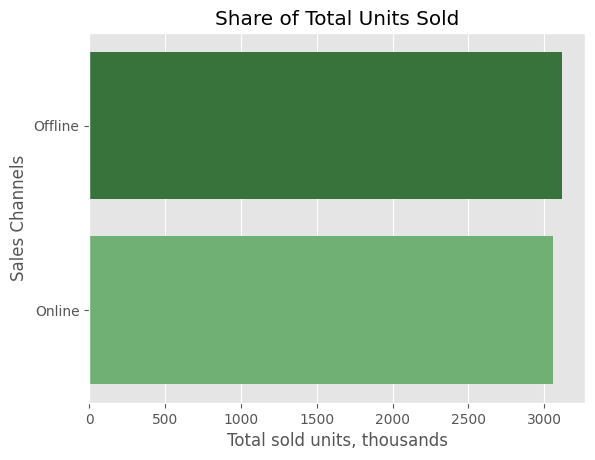

In [ ]:
sns.barplot(data=units_gouped, x='units_sold', y='sales_channel', errorbar=None, palette=['#2e7d32', '#66bb6a'])

plt.title('Share of Total Units Sold')
plt.xlabel('Total sold units, thousands')
plt.ylabel('Sales Channels')

plt.show()

Offline sells slightly more units (about 3.11 million) than Online (about 3.06 million), but the gap is small. Customers therefore buy almost the same volume of goods offline and online.

In [ ]:
rev_cos_prof = data_un.groupby('sales_channel')[['revenue', 'cost', 'profit']].sum().sort_values(by='revenue', ascending=False).reset_index()
rev_cos_prof_melted = rev_cos_prof.melt(id_vars='sales_channel', var_name='metric', value_name='amount')
rev_cos_prof_melted['amount'] = rev_cos_prof_melted['amount'] / 1000000
rev_cos_prof_melted

,sales_channel,metric,amount
0,Offline,revenue,810.030465
1,Online,revenue,788.953296
2,Offline,cost,571.519138
3,Online,cost,553.755588
4,Offline,profit,238.511327
5,Online,profit,235.197708


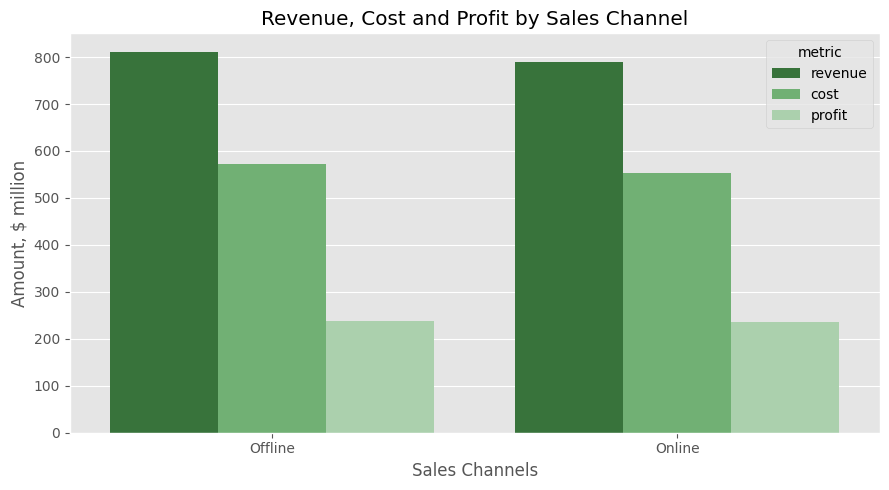

In [ ]:
plt.figure(figsize=(9, 5))
sns.barplot(data=rev_cos_prof_melted, x='sales_channel', y='amount', hue='metric', palette=['#2e7d32', '#66bb6a', '#a5d6a7'])
plt.title("Revenue, Cost and Profit by Sales Channel")
plt.xlabel('Sales Channels')
plt.ylabel('Amount, $ million')
plt.tight_layout()
plt.show()

The difference between the channels is small and in both channels costs take a similar part of revenue. This means that the two channels are almost equally profitable and neither one clearly dominates.

#Shipping time analysis

##Shipping time analysis by Product Category

In [ ]:
data_un.head()

,order_id,order_date,ship_date,order_priority,country_code,product_id,sales_channel,units_sold,unit_price,unit_cost,country,region,sub_region,category,revenue,cost,profit
0,100640618,2014-10-08,2014-10-18,Medium,NOR,2103,Online,650.0,205.70,117.11,Norway,Europe,Northern Europe,Cereal,133705.00,76121.50,57583.50
1,100983083,2016-08-11,2016-08-11,Critical,SRB,2103,Offline,1993.0,205.70,117.11,Serbia,Europe,Southern Europe,Cereal,409960.10,233400.23,176559.87
3,102230632,2017-05-13,2017-06-13,Low,MNE,2455,Online,1171.0,109.28,35.84,Montenegro,Europe,Southern Europe,Clothes,127966.88,41968.64,85998.24
4,103435266,2012-08-11,2012-09-18,High,SRB,1270,Offline,7648.0,47.45,31.79,Serbia,Europe,Southern Europe,Beverages,362897.60,243129.92,119767.68
5,103450715,2015-03-15,2015-04-18,High,SVK,8681,Online,2220.0,651.21,524.96,Slovakia,Europe,Eastern Europe,Office Supplies,1445686.20,1165411.20,280275.00


In [ ]:
data_un['shipping_days'] = (data_un['ship_date'] - data_un['order_date']).dt.days


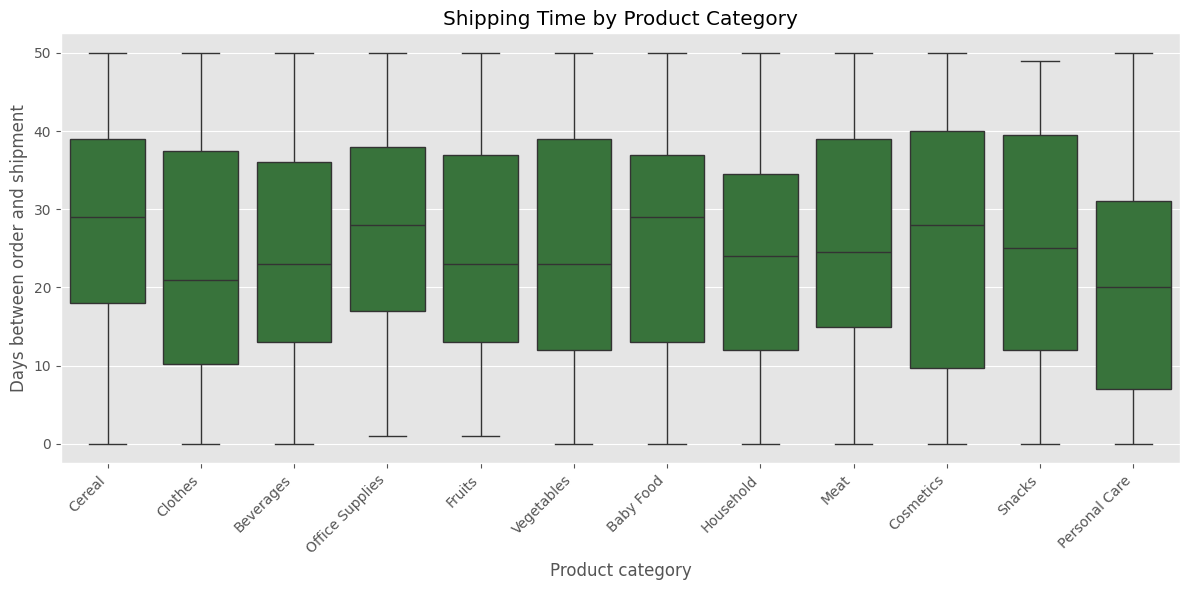

In [ ]:
plt.figure(figsize=(12, 6))
sns.boxplot(data=data_un, x='category', y='shipping_days', color='#2e7d32')
plt.title('Shipping Time by Product Category')
plt.xlabel('Product category')
plt.ylabel('Days between order and shipment')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

The boxplot compares the time between order and shipment across product categories. The distributions are very similar: in every category shipping takes from 0 to about 50 days, and the median is roughly 20 to 29 days. Personal Care and Clothes are slightly faster (medians around 20-21 days), while Cereal and Baby Food are slightly slower (around 29 days). However, the differences between categories are small compared with the spread inside each category, so the product category does not have a strong influence on shipping time.

##Shipping time analysis by Countries

The analysis is based on the median shipping time (days between order and shipment), not the mean. The median is used because it is not affected by extreme values: a few unusually fast or slow orders can noticeably shift the average, while the median shows the typical delivery time.

In [ ]:
top_10_fastest = data_un.groupby('country')['shipping_days'].median().sort_values().head(10).reset_index()
top_10_slowest = data_un.groupby('country')['shipping_days'].median().sort_values(ascending=False).head(10).reset_index()

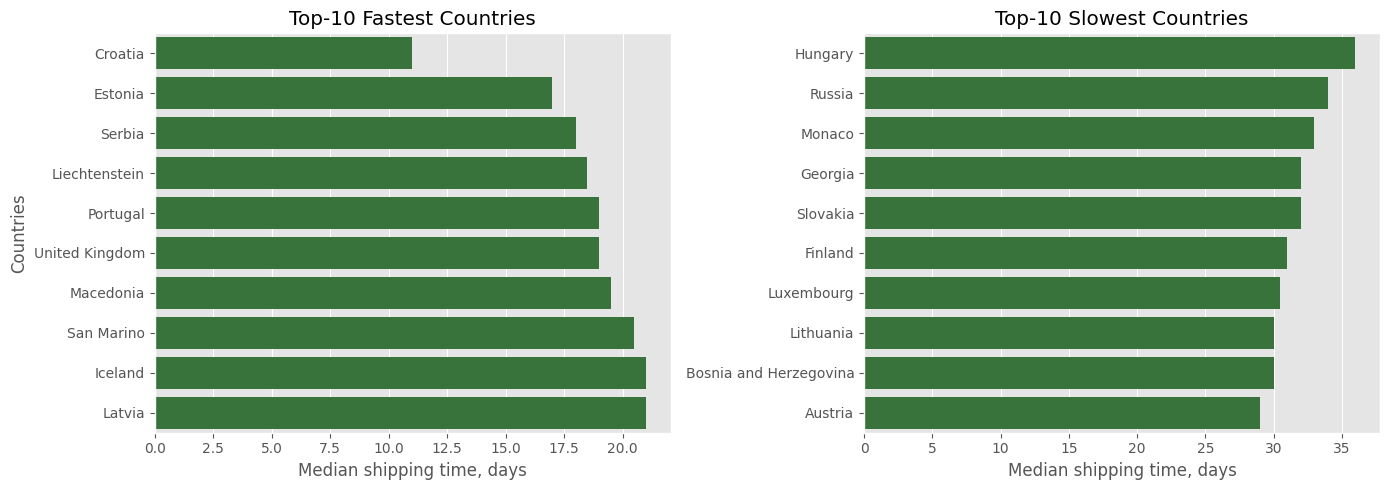

In [ ]:
fig, ax = plt.subplots(1, 2, figsize=(14, 5))

sns.barplot(data=top_10_fastest, x='shipping_days', y='country', errorbar=None, ax=ax[0], color='#2e7d32')
ax[0].set_title('Top-10 Fastest Countries')
ax[0].set_xlabel('Median shipping time, days')
ax[0].set_ylabel('Countries')

sns.barplot(data=top_10_slowest, x='shipping_days', y='country', errorbar=None, ax=ax[1], color='#2e7d32')
ax[1].set_title('Top-10 Slowest Countries')
ax[1].set_xlabel('Median shipping time, days')
ax[1].set_ylabel('')

plt.tight_layout()
plt.show()

The charts show the median time between order and shipment for the ten fastest and the ten slowest countries. In the fastest countries shipping takes roughly 11 to 21 days, with Croatia (about 11 days), Estonia and Serbia in the lead. In the slowest countries it takes about 29 to 36 days, with Hungary, Russia and Monaco at the top.

##Shipping time analysis by Regions

In [ ]:
grouped_by_region = data_un.groupby('region')['shipping_days'].median().sort_values().reset_index()
grouped_by_region

,region,shipping_days
0,Europe,25.0
1,Asia,25.5


The median time between order and shipment is almost the same in both regions: 25 days in Europe and 25.5 days in Asia.

#Relationship between Shipping Time and Profit

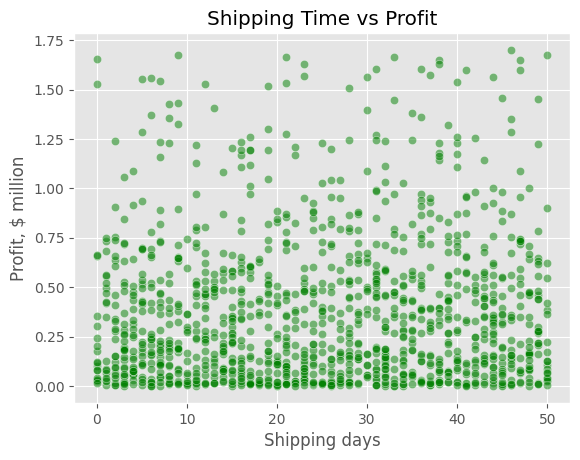

In [ ]:
sns.scatterplot(data=data_un, x='shipping_days', y=data_un['profit'] / 1000000, color='green', alpha=0.5)
plt.title('Shipping Time vs Profit')
plt.xlabel('Shipping days')
plt.ylabel('Profit, $ million')
plt.show()


In [ ]:
correlation = data_un[['shipping_days', 'profit']].corr()
correlation

,shipping_days,profit
shipping_days,1.000000,0.060695
profit,0.060695,1.000000


The scatterplot shows the relationship between shipping time and profit for individual orders. The points are spread all over the chart, and there is no visible trend: orders with short and long shipping times have a similar range of profits. The correlation coefficient calculated at the order level is about 0.06, which is close to zero and means that there is practically no linear relationship between shipping time and profit. Based on this data, there is no sign that faster or slower shipping affects profit.

#Sales Dynamics Over Time

##By Product Categories

In [ ]:
print(data_un['order_date'].min())
print(data_un['order_date'].max())

2010-01-01 00:00:00
2017-07-22 00:00:00


In [ ]:
dyn = data_un.copy()
dyn['year'] = dyn['order_date'].dt.year

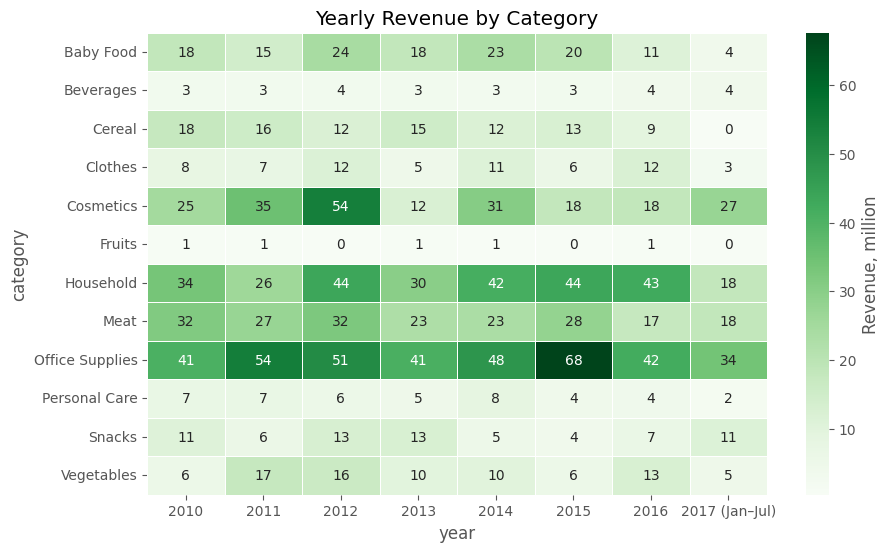

In [ ]:
pt_year = dyn.pivot_table(index='category', columns='year', values='revenue', aggfunc='sum', fill_value=0) / 1000000
pt_year = pt_year.rename(columns={2017: '2017 (Jan–Jul)'})

plt.figure(figsize=(10, 6))
sns.heatmap(pt_year, annot=True, fmt='.0f', cmap='Greens', linewidths=0.5, cbar_kws={'label': 'Revenue, million'})
plt.title('Yearly Revenue by Category')
plt.show()

Office Supplies has the highest revenue in every full year (peak of 68 million in 2015). Household stayed high from 2014 to 2016, Cosmetics changes a lot from year to year, and Meat, Cereal and Baby Food slowly decline. Beverages, Fruits and Personal Care are small and stable. There is no single trend for all categories, and the year 2017 covers only January–July, so it cannot be compared directly with the full years.

##By Product Counries

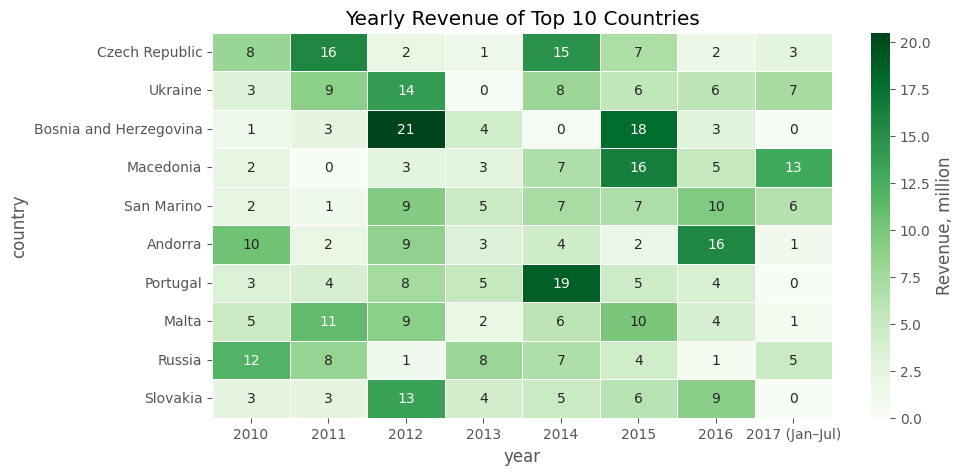

In [ ]:
top_countries = dyn.groupby('country')['revenue'].sum().nlargest(10).index

pt_country = dyn[dyn['country'].isin(top_countries)].pivot_table(
    index='country', columns='year', values='revenue', aggfunc='sum', fill_value=0) / 1000000
pt_country = pt_country.loc[top_countries].rename(columns={2017: '2017 (Jan–Jul)'})

plt.figure(figsize=(10, 5))
sns.heatmap(pt_country, annot=True, fmt='.0f', cmap='Greens', linewidths=0.5, cbar_kws={'label': 'Revenue, million'})
plt.title('Yearly Revenue of Top 10 Countries')
plt.show()

The dataset has 45 countries, and showing all of them on one chart would be unreadable. So only the top 10 countries by total revenue for the whole period are shown. The countries are chosen by their total revenue in 2010–2017, and then the yearly revenue is shown for each of them.

The top 10 countries have no stable leader: the revenue of each country jumps a lot from year to year, and the peaks usually last one year. For example, Bosnia and Herzegovina had 21 million in 2012 and 18 million in 2015, but only 0–4 million in other years, and Portugal peaked in 2014 (19 million). Russia is the only country with a clear decline (from 12 million in 2010 to 1 million in 2016).

##By Regions

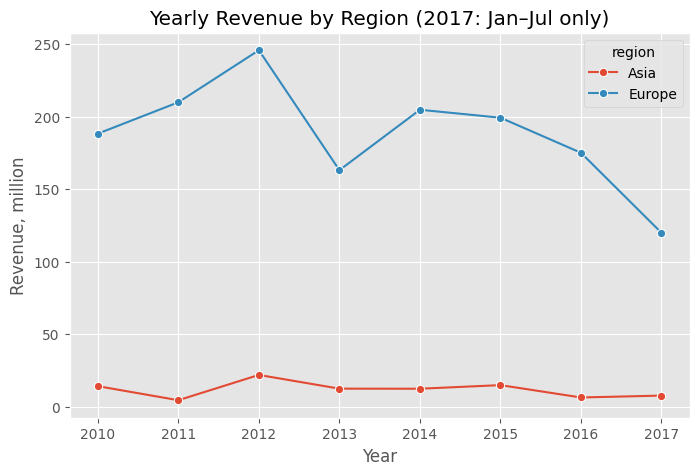

In [ ]:
reg = dyn.pivot_table(index='year', columns='region', values='revenue', aggfunc='sum', fill_value=0) / 1000000

plt.figure(figsize=(8, 5))
sns.lineplot(data=reg, marker='o', dashes=False)
plt.title('Yearly Revenue by Region (2017: Jan–Jul only)')
plt.xlabel('Year')
plt.ylabel('Revenue, million')
plt.show()

Europe gives most of the revenue in every year. Its revenue grew from about 190 million in 2010 to a peak of about 245 million in 2012, then fell sharply in 2013 (about 165 million), partly recovered in 2014–2015 (about 200 million) and has been going down since then (about 175 million in 2016). The year 2017 covers only January–July, so its lower value cannot be compared directly with full years. Asia is much smaller (roughly 5–20 million per year) and stays almost flat, with a small peak in 2012, the same year as Europe.

#Sales Analysis by Weekday

In [ ]:
data_un['weekday'] = data_un['order_date'].dt.weekday
data_un.head()

,order_id,order_date,ship_date,order_priority,country_code,product_id,sales_channel,units_sold,unit_price,unit_cost,country,region,sub_region,category,revenue,cost,profit,shipping_days,weekday
0,100640618,2014-10-08,2014-10-18,Medium,NOR,2103,Online,650.0,205.70,117.11,Norway,Europe,Northern Europe,Cereal,133705.00,76121.50,57583.50,10,2
1,100983083,2016-08-11,2016-08-11,Critical,SRB,2103,Offline,1993.0,205.70,117.11,Serbia,Europe,Southern Europe,Cereal,409960.10,233400.23,176559.87,0,3
3,102230632,2017-05-13,2017-06-13,Low,MNE,2455,Online,1171.0,109.28,35.84,Montenegro,Europe,Southern Europe,Clothes,127966.88,41968.64,85998.24,31,5
4,103435266,2012-08-11,2012-09-18,High,SRB,1270,Offline,7648.0,47.45,31.79,Serbia,Europe,Southern Europe,Beverages,362897.60,243129.92,119767.68,38,5
5,103450715,2015-03-15,2015-04-18,High,SVK,8681,Online,2220.0,651.21,524.96,Slovakia,Europe,Eastern Europe,Office Supplies,1445686.20,1165411.20,280275.00,34,6


In [ ]:
pivot_table = pd.pivot_table(data=data_un,
                             index='category',
                             columns='weekday',
                             values='units_sold',
                             aggfunc='sum',
                             fill_value=0)
pivot_table

weekday,0,1,2,3,4,5,6
category,,,,,,,
Baby Food,57826.0,85446.0,63669.0,66324.0,77595.0,88333.0,85072.0
Beverages,95311.0,80268.0,75604.0,85538.0,49814.0,102630.0,88826.0
Cereal,41674.0,54752.0,58217.0,56201.0,62637.0,96269.0,90516.0
Clothes,68109.0,122600.0,43538.0,88375.0,53210.0,100874.0,102607.0
Cosmetics,55888.0,81409.0,68610.0,54482.0,132147.0,65086.0,48566.0
Fruits,85999.0,42790.0,85792.0,56175.0,34115.0,97302.0,128962.0
Household,105451.0,20474.0,91759.0,46726.0,52271.0,56825.0,43802.0
Meat,84843.0,78893.0,79850.0,65817.0,44597.0,72028.0,51205.0
Office Supplies,88724.0,72508.0,90861.0,77606.0,105888.0,53669.0,92225.0


In [ ]:
pivot_table.columns = ['Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday', 'Saturday', 'Sunday']
pivot_table

,Monday,Tuesday,Wednesday,Thursday,Friday,Saturday,Sunday
category,,,,,,,
Baby Food,57826.0,85446.0,63669.0,66324.0,77595.0,88333.0,85072.0
Beverages,95311.0,80268.0,75604.0,85538.0,49814.0,102630.0,88826.0
Cereal,41674.0,54752.0,58217.0,56201.0,62637.0,96269.0,90516.0
Clothes,68109.0,122600.0,43538.0,88375.0,53210.0,100874.0,102607.0
Cosmetics,55888.0,81409.0,68610.0,54482.0,132147.0,65086.0,48566.0
Fruits,85999.0,42790.0,85792.0,56175.0,34115.0,97302.0,128962.0
Household,105451.0,20474.0,91759.0,46726.0,52271.0,56825.0,43802.0
Meat,84843.0,78893.0,79850.0,65817.0,44597.0,72028.0,51205.0
Office Supplies,88724.0,72508.0,90861.0,77606.0,105888.0,53669.0,92225.0


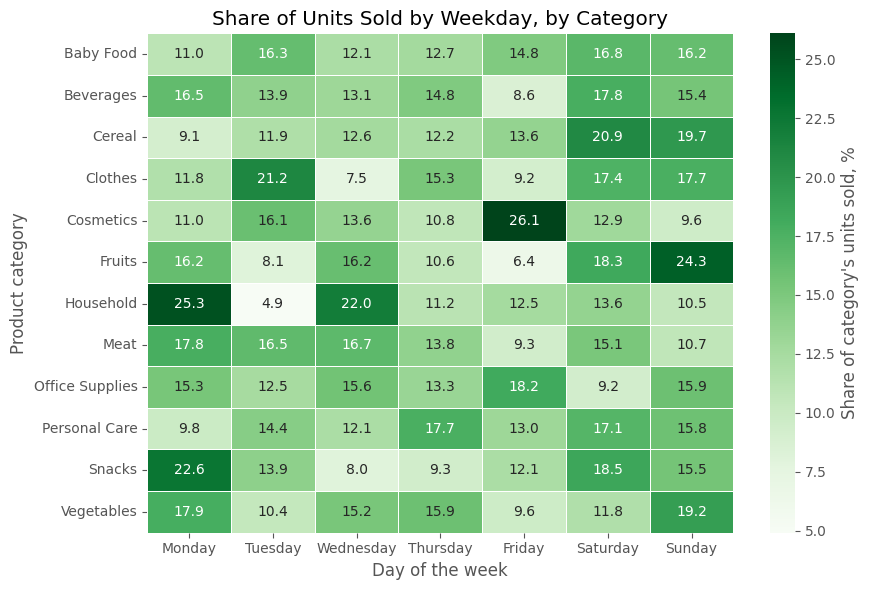

In [ ]:
plt.figure(figsize=(9, 6))
pivot_pct = pivot_table.div(pivot_table.sum(axis=1), axis=0) * 100
sns.heatmap(pivot_pct, annot=True, fmt='.1f', cmap='Greens', linewidths=0.5, cbar_kws={'label': 'Share of category\'s units sold, %'})
plt.title('Share of Units Sold by Weekday, by Category')
plt.xlabel('Day of the week')
plt.ylabel('Product category')
plt.xticks(rotation=0)

plt.tight_layout()
plt.show()

To analyze sales by day of the week, we chose a heat map because it allows us to compare 12 categories and 7 days at the same time, and the color intensity immediately shows on which days a category sells better. We used percentages (the share of category sales for each day) rather than absolute numbers because the categories vary greatly in volume: if we used raw values, the colors would only show the size of the category, not which days it sells better. Percentages make the categories comparable, and an even distribution corresponds to approximately 14% per day.

Some categories lean toward certain days, for example Cosmetics on Friday (26%), Household on Monday (25%) and Fruits on Sunday (24%), while Baby Food and Personal Care are more even. However, each category has only about 100 orders (roughly 15 per day), and one large order can change a share by several percentage points. So these are only tendencies, not a confirmed weekly pattern, and they are not enough to plan promotions by weekday or to call any product seasonal.

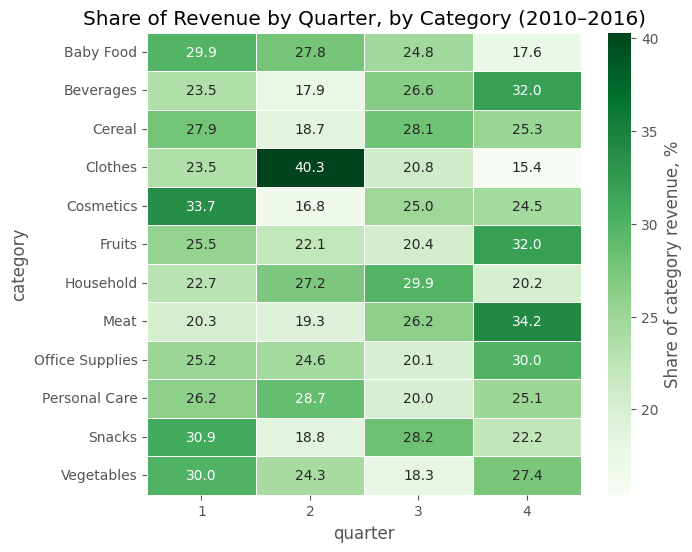

In [ ]:
season = data_un.copy()
season['year'] = season['order_date'].dt.year
season['quarter'] = season['order_date'].dt.quarter
season = season[season['year'] <= 2016]

pt = season.pivot_table(index='category', columns='quarter', values='revenue', aggfunc='sum')
pt_pct = pt.div(pt.sum(axis=1), axis=0) * 100

plt.figure(figsize=(7, 6))
sns.heatmap(pt_pct, annot=True, fmt='.1f', cmap='Greens', linewidths=0.5, cbar_kws={'label': 'Share of category revenue, %'})
plt.title('Share of Revenue by Quarter, by Category (2010–2016)')
plt.show()

In [ ]:
yq = season.pivot_table(index=['category', 'year'], columns='quarter', values='revenue', aggfunc='sum')
top_q = yq.idxmax(axis=1).unstack('year')
top_q

year,2010,2011,2012,2013,2014,2015,2016
category,,,,,,,
Baby Food,1,1,2,1,3,2,1
Beverages,1,3,4,4,2,3,1
Cereal,1,4,3,3,3,4,4
Clothes,3,2,2,2,2,2,3
Cosmetics,3,4,1,4,1,2,3
Fruits,3,4,1,1,4,3,2
Household,3,2,1,1,3,4,3
Meat,4,4,3,4,2,1,3
Office Supplies,2,3,1,1,2,4,2


I checked all 12 categories for the full years 2010–2016 (2017 is not included because it ends in July). On the heatmap some categories have a quarter with a higher share of revenue, but to see if this repeats, I also checked which quarter was the strongest in each year. Only Clothes looks seasonal: Q2 (April–June) was the strongest quarter in 5 of 7 years, and it has the highest quarter share (40%). For all other categories the strongest quarter changes from year to year, so there is no stable seasonality. As each category has only about 15 orders per year, even the Clothes result should be treated as a tendency, not a proven rule.

#Summary
1. General picture. In this project I analysed the sales of a company that sells goods in shops and online. In general, the company is profitable: about 30% of its revenue stays as profit. Almost all sales come from Europe. The changes over time are shown for all years from 2010 to July 2017, and the incomplete year 2017 is marked and not compared directly with the full years.

2. Product categories. Office Supplies, Household, Cosmetics and Meat bring the most revenue, and Cosmetics brings the most profit. Fruits, Beverages and Personal Care have the lowest profit, but mainly because their revenue is small, and their margins (26–33%) are close to the overall margin of about 30%. The lowest margins are in Meat (14%), Office Supplies (19%) and Household (25%). Their revenue is large, so the company should check prices and costs in these categories first.

3. Geography. Europe gives about 94% of revenue and 95% of profit, and Asia only 5–7%, so the difference between the regions is mostly about size. Among countries, the leaders by revenue (Czech Republic, Ukraine, Bosnia and Herzegovina) have similar results, but by profit the top is different: Andorra, Ukraine and Malta are first, and the Czech Republic is only seventh. So the biggest market is not always the most profitable one. Asia could be a growth opportunity, but it has few orders, so conclusions about it are less reliable.

4. Dynamics over time. Revenue in Europe, which gives most of the sales, peaked in 2012, fell sharply in 2013, partly recovered in 2014–2015 and has been going down since then, while Asia is small and almost flat. Office Supplies is the biggest category in every year, while Meat, Cereal and Baby Food slowly decline. Revenue of single countries jumps a lot from year to year (probably because of a small number of large orders), so no stable trend can be confirmed for them.

5. Sales channels. Online and offline are almost equal in revenue, profit and units sold (the difference is only about 2–3%). It means that both channels are important and should be developed together.

6. Shipping time. The typical time between order and shipment is about 20–29days for all categories and about 25 days in both regions, so category and region do not explain the delays. Country matters more: from about 11 days in Croatia to about 36 days in Hungary. It could be worth checking the logistics in the slowest countries, such as Hungary, Russia and Monaco.

7. Shipping time and profit. The correlation between shipping time and profit of an order is about 0.06, which means there is practically no relationship. Slower or faster delivery does not change the profit of an order, so profit depends on other things, such as the product and the quantity. The company can work on delivery speed (for example, in the slowest countries) to improve customer service, but it should not expect it to change profit.

8. Days of the week. In most categories sales are spread fairly evenly across the week (about 14% per day). Some categories have days with a higher share (for example, Cosmetics on Friday), but each category has only about 100 orders, so one large order can change a share a lot. These differences may be random, so they should not be used to plan promotions without more data.

9. Seasonality. Checked for all categories in 2010–2016. Only Clothes looks seasonal; other categories have no stable seasonal pattern.